# Corrective RAG with Ambiguous Retrieval



This notebook extends the previous Corrective RAG pipeline by handling **AMBIGUOUS retrieval using both local documents and web search results**.

### 1. Workflow

```text
User Question → FAISS Retrieval → LLM Evaluator
                                      |
                     ┌────────────────┼────────────────┐
                     ▼                ▼                ▼
                  CORRECT         INCORRECT        AMBIGUOUS
                     |                |                |
                 Local Docs      Rewrite Query    Rewrite Query
                     |                |                |
                     |           Tavily Search     Tavily Search
                     |                |                |
                     |            Web Docs       Local + Web Docs
                     |                |                |
                     └────────────────┼────────────────┘
                                      ▼
                          Decompose → Filter → Recompose
                                      |
                                Generate Answer
                                      |
                                     END
```

### 2. Main Components

| Component | Description |
|---|---|
| **FAISS** | Retrieves the top 4 relevant document chunks. |
| **LLM Evaluator** | Scores each chunk between 0 and 1. |
| **Query Rewriter** | Generates optimized web-search keywords. |
| **Tavily Search** | Retrieves up to 5 web results. |
| **Refinement** | Decomposes, filters, and recomposes relevant sentences. |
| **LangGraph** | Manages conditional routing and workflow execution. |

### 3. Evaluation and Routing

- **CORRECT:** Any score > 0.7 → use local documents scoring > 0.3.
- **INCORRECT:** All scores < 0.3 → rewrite query and use web results.
- **AMBIGUOUS:** Otherwise → rewrite query and combine local documents scoring > 0.3 with web results.

All three routes eventually proceed to refinement and answer generation.

### 4. What's New?

Unlike the previous notebook, the **AMBIGUOUS branch no longer terminates**. Instead, it supplements partially relevant local knowledge with external information.

### Key Takeaway

**Ambiguous retrieval → Query rewriting → Web search → Hybrid context refinement → Grounded answer**

This approach can improve answer completeness by combining existing knowledge with web results.

**Limitations:** Web results are not independently evaluated, and the system has no automatic retry or citation-verification mechanism.

In [1]:
from typing import List, TypedDict, Literal
from pydantic import BaseModel
import re
import os

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv

from langchain_community.tools.tavily_search import TavilySearchResults

load_dotenv()

api_key = os.getenv("OPENAI_API_KEY")
base_url = os.getenv("BASE_URL")

C:\Users\meisa\AppData\Local\Temp\ipykernel_107720\2436815219.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader
W1102 12:15:39.699000 107720 Lib\site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1102 12:15:39.732000 107720 Lib\site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


In [2]:
docs = (
    PyPDFLoader("./documents/ML Book.pdf").load()
)

In [3]:
chunks = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150).split_documents(docs)
for d in chunks:
    d.page_content = d.page_content.encode("utf-8", "ignore").decode("utf-8", "ignore")


In [4]:
#embeddings = OpenAIEmbeddings(model="text-embedding-3-large")

from langchain_huggingface import HuggingFaceEmbeddings

hf_embeddings = HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')

vector_store = FAISS.from_documents(chunks, hf_embeddings)
retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})

In [5]:
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0,api_key=api_key, base_url=base_url)

In [6]:
UPPER_TH = 0.7
LOWER_TH = 0.3

In [7]:
# -----------------------------
# State
# -----------------------------
class State(TypedDict):
    question: str

    docs: List[Document]
    good_docs: List[Document]

    verdict: str
    reason: str

    strips: List[str]
    kept_strips: List[str]
    refined_context: str

    web_query: str
    
    web_docs: List[Document]

    answer: str

In [8]:
# -----------------------------
# Retrieve
# -----------------------------
def retrieve_node(state: State) -> State:
    q = state["question"]
    return {"docs": retriever.invoke(q)}


In [9]:
# -----------------------------
# Score-based doc evaluator
# -----------------------------
class DocEvalScore(BaseModel):
    score: float
    reason: str


doc_eval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a strict retrieval evaluator for RAG.\n"
            "You will be given ONE retrieved chunk and a question.\n"
            "Return a relevance score in [0.0, 1.0].\n"
            "- 1.0: chunk alone is sufficient to answer fully/mostly\n"
            "- 0.0: chunk is irrelevant\n"
            "Be conservative with high scores.\n"
            "Also return a short reason.\n"
            "Output JSON only.",
        ),
        ("human", "Question: {question}\n\nChunk:\n{chunk}"),
    ]
)

doc_eval_chain = doc_eval_prompt | llm.with_structured_output(DocEvalScore)


def eval_each_doc_node(state: State) -> State:
    q = state["question"]
    scores: List[float] = []
    good: List[Document] = []

    for d in state["docs"]:
        out = doc_eval_chain.invoke({"question": q, "chunk": d.page_content})
        scores.append(out.score)

        # Keep any doc above LOWER_TH as "weakly relevant"
        if out.score > LOWER_TH:
            good.append(d)

    # CORRECT: at least one doc > UPPER_TH
    if any(s > UPPER_TH for s in scores):
        return {
            "good_docs": good,
            "verdict": "CORRECT",
            "reason": f"At least one retrieved chunk scored > {UPPER_TH}.",
        }

    # INCORRECT: all docs < LOWER_TH
    if len(scores) > 0 and all(s < LOWER_TH for s in scores):
        return {
            "good_docs": [],
            "verdict": "INCORRECT",
            "reason": f"All retrieved chunks scored < {LOWER_TH}.",
        }

    # AMBIGUOUS: otherwise
    return {
        "good_docs": good,
        "verdict": "AMBIGUOUS",
        "reason": f"No chunk scored > {UPPER_TH}, but not all were < {LOWER_TH}.",
    }


In [10]:
# -----------------------------
# Sentence-level DECOMPOSER
# -----------------------------
def decompose_to_sentences(text: str) -> List[str]:
    text = re.sub(r"\s+", " ", text).strip()
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return [s.strip() for s in sentences if len(s.strip()) > 20]


# -----------------------------
# FILTER (LLM judge)
# -----------------------------
class KeepOrDrop(BaseModel):
    keep: bool


filter_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a relevance filter.\n"
            "Return keep=true if the sentence contains relevant information, news, or context related to the question.\n"
            "Use ONLY the sentence. Output JSON only.",
        ),
        ("human", "Question: {question}\n\nSentence:\n{sentence}"),
    ]
)

filter_chain = filter_prompt | llm.with_structured_output(KeepOrDrop)


# -----------------------------
# Knowledge refinement
# (CORRECT => internal only)
# (INCORRECT => web only)
# (AMBIGUOUS => internal + web)
# -----------------------------
def refine(state: State) -> State:
    q = state["question"]

    if state.get("verdict") == "CORRECT":
        docs_to_use = state["good_docs"]
    elif state.get("verdict") == "INCORRECT":
        docs_to_use = state["web_docs"]
    else:  # AMBIGUOUS
        docs_to_use = state["good_docs"] + state["web_docs"]

    context = "\n\n".join(d.page_content for d in docs_to_use).strip()

    strips = decompose_to_sentences(context)

    kept: List[str] = []
    for s in strips:
        if filter_chain.invoke({"question": q, "sentence": s}).keep:
            kept.append(s)

    refined_context = "\n".join(kept).strip()

    return {
        "strips": strips,
        "kept_strips": kept,
        "refined_context": refined_context,
    }


In [11]:
# -----------------------------
# Query rewrite for web search
# -----------------------------
class WebQuery(BaseModel):
    query: str


rewrite_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Rewrite the user question into a web search query composed of keywords.\n"
            "Rules:\n"
            "- Keep it short (6–14 words).\n"
            "- If the question implies recency (e.g., recent/latest/last week/last month), add a constraint like (last 30 days).\n"
            "- Do NOT answer the question.\n"
            "- Return JSON with a single key: query",
        ),
        ("human", "Question: {question}"),
    ]
)

rewrite_chain = rewrite_prompt | llm.with_structured_output(WebQuery)


def rewrite_query_node(state: State) -> State:
    out = rewrite_chain.invoke({"question": state["question"]})
    return {"web_query": out.query}


# -----------------------------
# Web search node: uses web_query
# -----------------------------
tavily = TavilySearchResults(max_results=5)


def web_search_node(state: State) -> State:
    q = state.get("web_query") or state["question"]
    results = tavily.invoke({"query": q})

    web_docs: List[Document] = []
    for r in results or []:
        title = r.get("title", "")
        url = r.get("url", "")
        content = r.get("content", "") or r.get("snippet", "")
        text = f"TITLE: {title}\nURL: {url}\nCONTENT:\n{content}"
        web_docs.append(Document(page_content=text, metadata={"url": url, "title": title}))

    return {"web_docs": web_docs}


C:\Users\meisa\AppData\Local\Temp\ipykernel_107720\4242330831.py:34: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tavily = TavilySearchResults(max_results=5)


In [12]:
# -----------------------------
# Generate
# -----------------------------
answer_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a helpful ML tutor. Answer ONLY using the provided context.\n"
            "If the context is empty or insufficient, say: 'I don't know.'",
        ),
        ("human", "Question: {question}\n\nContext:\n{context}"),
    ]
)


def generate(state: State) -> State:
    out = (answer_prompt | llm).invoke({"question": state["question"], "context": state["refined_context"]})
    return {"answer": out.content}


In [13]:
# -----------------------------
# Routing
# CORRECT => refine
# INCORRECT / AMBIGUOUS => rewrite -> web_search -> refine -> generate
# -----------------------------
def route_after_eval(state: State) -> str:
    if state["verdict"] == "CORRECT":
        return "refine"
    else:
        return "rewrite_query"


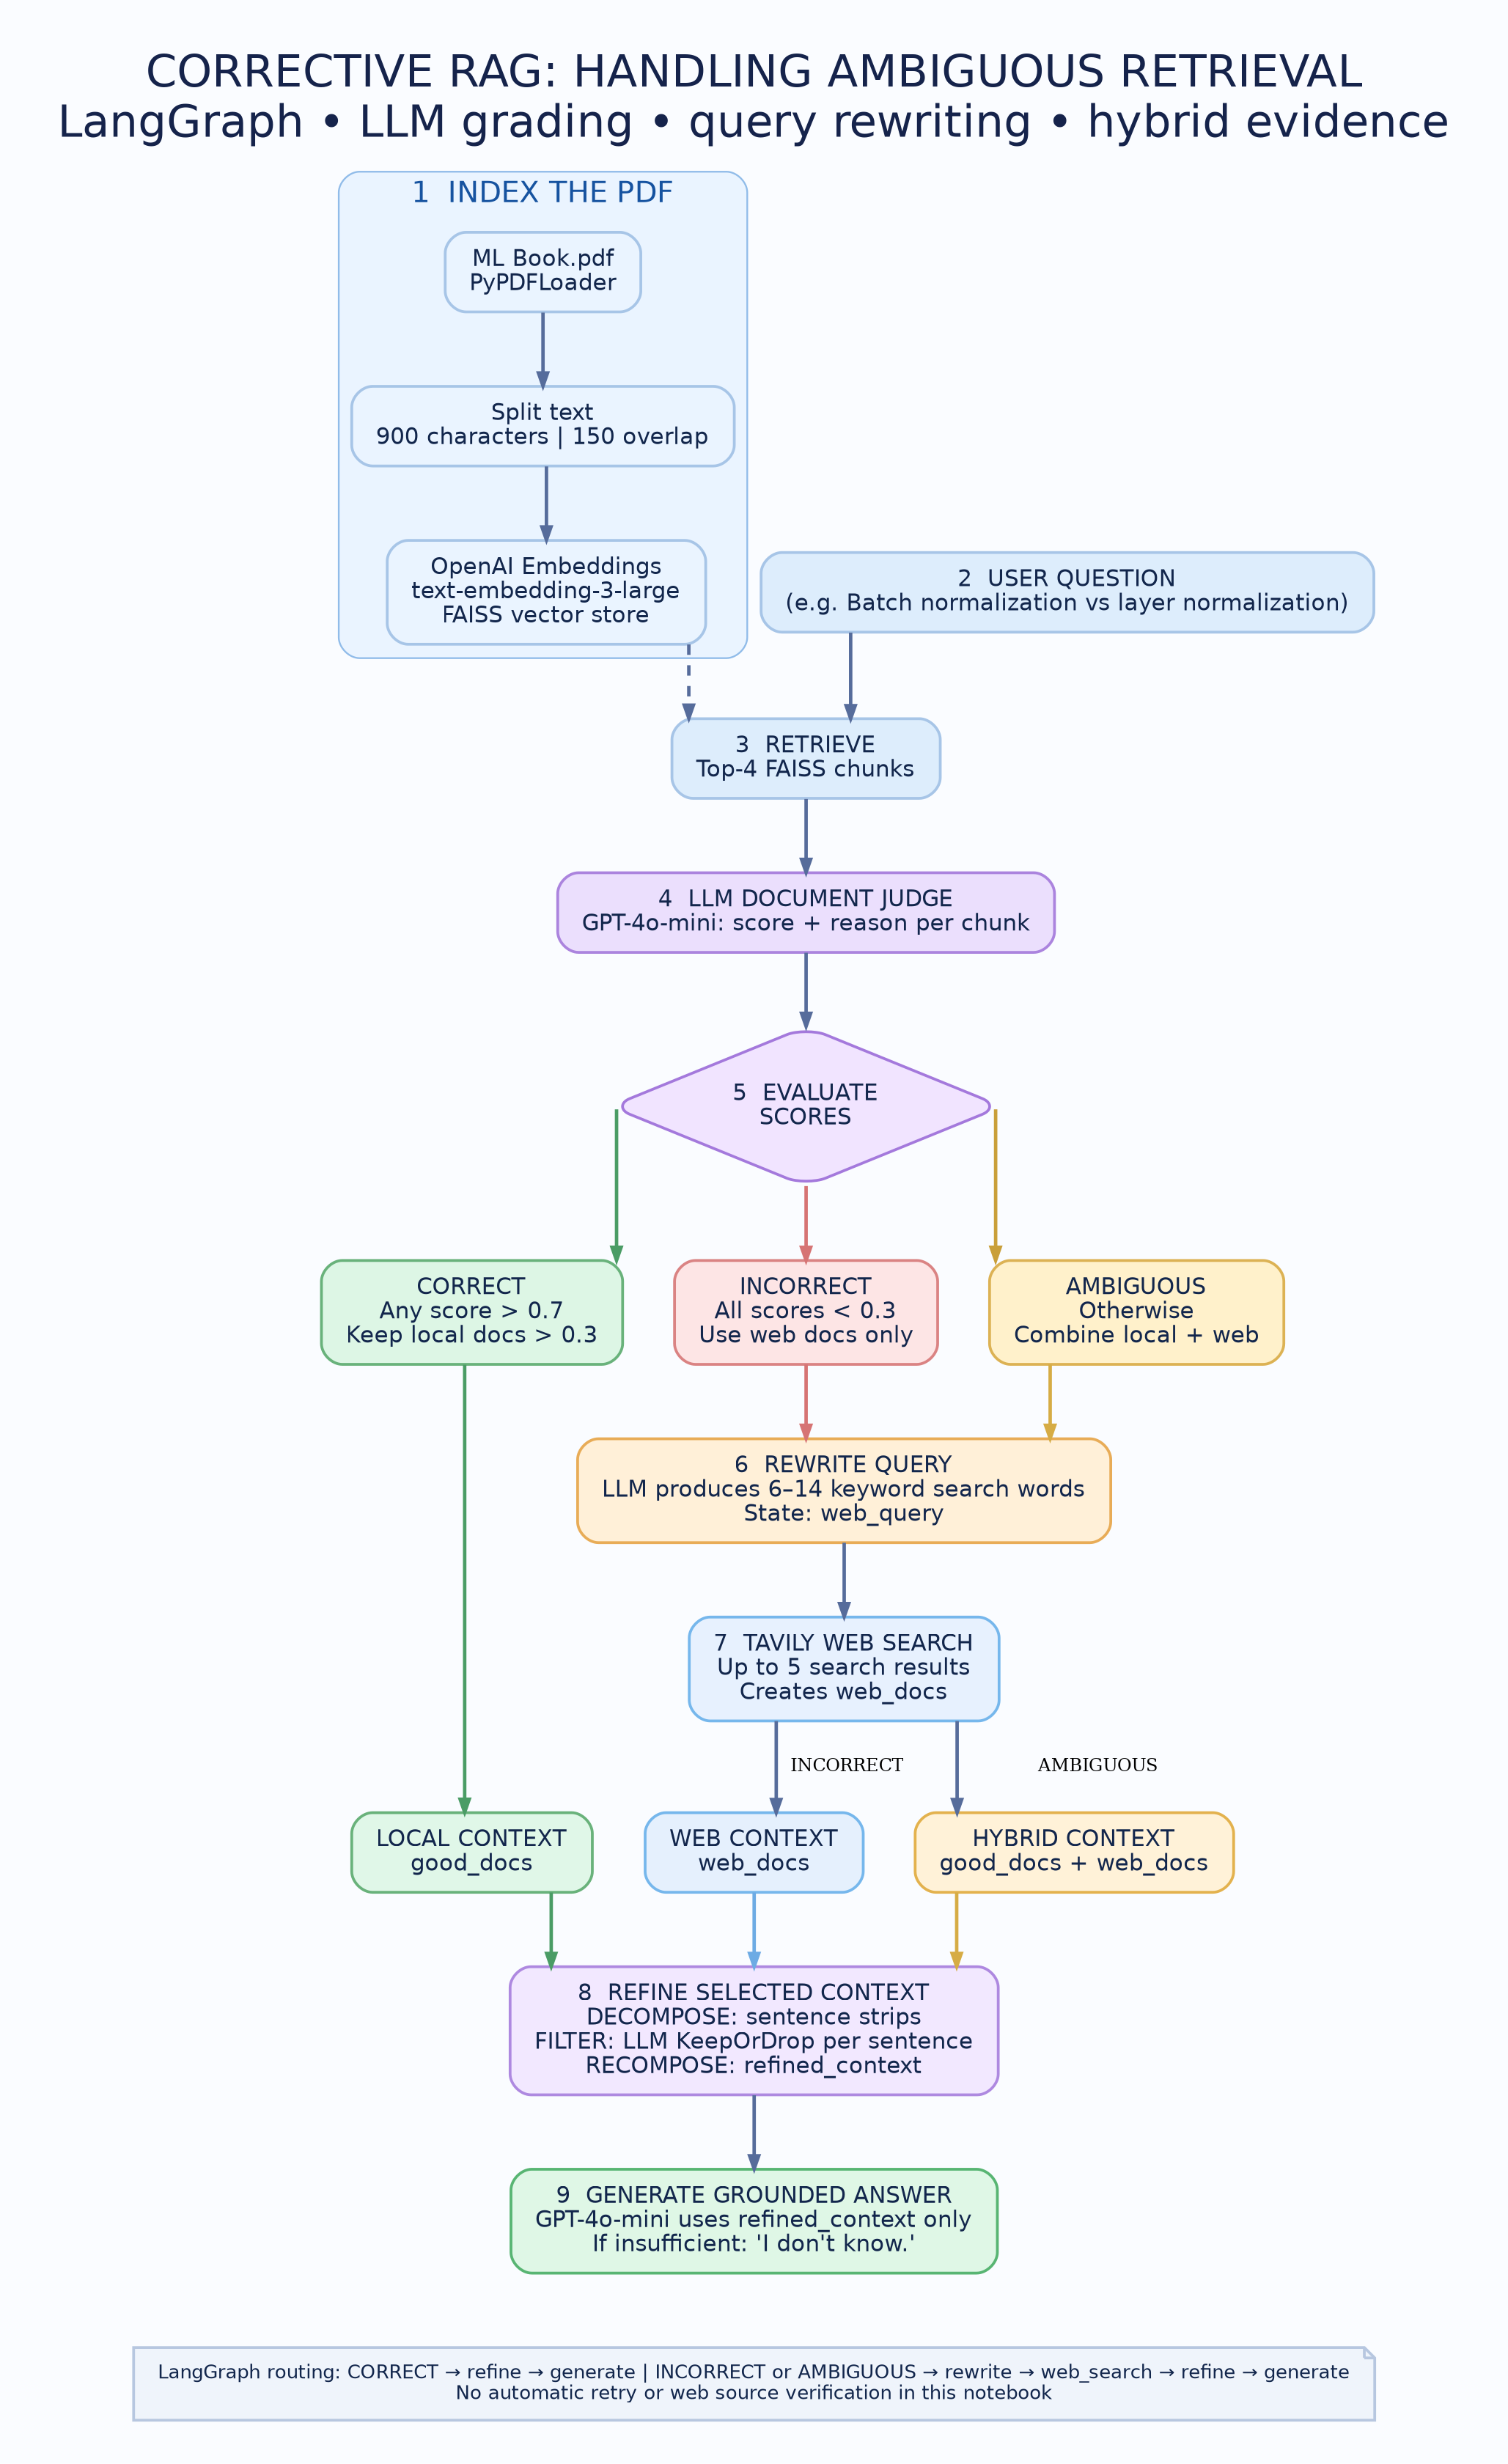

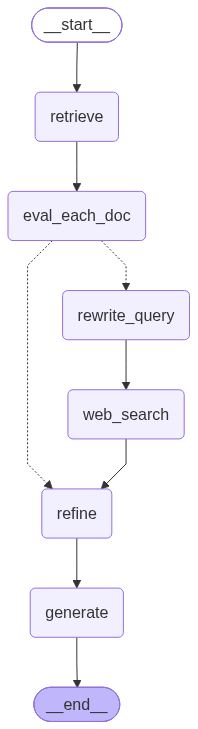

In [14]:
# -----------------------------
# Build graph
# -----------------------------
g = StateGraph(State)

g.add_node("retrieve", retrieve_node)
g.add_node("eval_each_doc", eval_each_doc_node)

g.add_node("rewrite_query", rewrite_query_node)
g.add_node("web_search", web_search_node)

g.add_node("refine", refine)
g.add_node("generate", generate)

g.add_edge(START, "retrieve")
g.add_edge("retrieve", "eval_each_doc")

g.add_conditional_edges(
    "eval_each_doc",
    route_after_eval,
    {
        "refine": "refine",
        "rewrite_query": "rewrite_query",
    },
)

# non-correct path
g.add_edge("rewrite_query", "web_search")
g.add_edge("web_search", "refine")

# correct path already goes to refine
g.add_edge("refine", "generate")
g.add_edge("generate", END)

app = g.compile()

app


In [15]:
# -----------------------------
# Run example
# -----------------------------
res = app.invoke(
    {
        "question": "Batch normalization vs layer normalization",
        "docs": [],
        "good_docs": [],
        "verdict": "",
        "reason": "",
        "strips": [],
        "kept_strips": [],
        "refined_context": "",
        "web_query": "",
        "web_docs": [],
        "answer": "",
    }
)

print("VERDICT:", res["verdict"])
print("REASON:", res["reason"])
print("WEB_QUERY:", res["web_query"])
print("\nOUTPUT:\n", res["answer"])


VERDICT: AMBIGUOUS
REASON: No chunk scored > 0.7, but not all were < 0.3.
WEB_QUERY: Batch normalization vs layer normalization

OUTPUT:
 **Batch Normalization vs Layer Normalization**

1. **Definition**:
   - **Batch Normalization (BN)**: Normalizes activations across the mini-batch dimension. It computes the mean and variance for each feature across all examples in the batch.
   - **Layer Normalization (LN)**: Normalizes activations across the feature dimension for each individual example, independently of the batch size.

2. **Use Cases**:
   - **Batch Normalization**: Best suited for Convolutional Neural Networks (CNNs) with large batch sizes, as it stabilizes training dynamics and accelerates convergence.
   - **Layer Normalization**: Ideal for sequence models like Recurrent Neural Networks (RNNs) and Transformers, especially when batch sizes are small or variable, as it does not depend on batch statistics.

3. **Advantages**:
   - **Batch Normalization**: Enables higher learning 

In [17]:
print(res['web_query'])
print(res['web_docs'])
print(res['good_docs'])

Batch normalization vs layer normalization
[Document(metadata={'url': 'https://zilliz.com/learn/layer-vs-batch-normalization-unlocking-efficiency-in-neural-networks', 'title': 'Batch vs Layer Normalization - Zilliz Learn'}, page_content="TITLE: Batch vs Layer Normalization - Zilliz Learn\nURL: https://zilliz.com/learn/layer-vs-batch-normalization-unlocking-efficiency-in-neural-networks\nCONTENT:\nLayer normalization and batch normalization offer complementary approaches to addressing the challenges of internal covariate shift and stabilizing the training process. While batch normalization excels in stabilizing training dynamics and accelerating convergence, layer normalization offers greater flexibility and robustness, especially in scenarios with small batch sizes or fluctuating data distributions.\n\nBy understanding their strengths and limitations, practitioners can make informed decisions in model design and training, ultimately leading to more efficient and effective neural networ